# Competición: ¡Cliente a la fuga!
**Equipo:** Pytones

**Participantes:** Mario Rosete Lázaro, Jorge Tamirat Montes Nocete, Guillermo Martínez Ortigosa, Roberto Hernando Ascaso, Jaime de Vera Martín, Juan Andrés Cabrera Taramasco

En este cuaderno presentamos el despliegue de nuestro modelo final para la predicción de fuga de clientes. Nuestro enfoque se ha centrado en tres pilares fundamentales exigidos por el negocio:
1. **Rigor Estadístico:** Prevención absoluta de la "Fuga de Información" aislando el conjunto de Test.
2. **Interpretabilidad total ("Cero Cajas Negras"):** Purificación paramétrica del modelo agrupando categorías para lograr p-valores significativos en el 100% de las variables.
3. **Visión de Negocio (Maximización de Youden):** Cálculo matemático del umbral óptimo en la curva ROC para huir de la métrica engañosa del *Accuracy* por el desbalance de la variable objetivo y priorizar el rescate real de clientes (Sensibilidad).

In [2]:
# Importar librerias
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from statsmodels.formula.api import logit
from google.colab import drive
drive.mount('/content/drive') # Permite acceder al Drive
os.chdir("/content/drive/MyDrive/Trabajo_Pytones") # Cambio de directorio

Mounted at /content/drive


### 1. Lectura de Datos y Preparación Inicial
* Procedemos a la carga de los datos históricos de entrenamiento y del conjunto ciego de validación (Test).
* Para garantizar la compatibilidad estructural entre ambos conjuntos de datos, procedemos a alinear sus esquemas. Corregimos la discrepancia existente renombrando la variable `Antig.edad` del Test como `Antiguedad`. Esta unificación es un requisito técnico indispensable para que el algoritmo pueda proyectar correctamente los patrones aprendidos en el Train sobre el archivo ciego.
* Para evitar que variables sin poder predictivo introduzcan ruido o generen correlaciones falsas, pasamos la variable `ID` directamente al índice de los *DataFrames*, excluyéndola del entrenamiento matemático.
* Asimismo, aseguramos el tipo correcto de la variable `Mayor65` ya que no nos interesa que sea una variable numérica, sino una variable categórica ya que son únicamente 0 y 1 los valores presentes en esta variable.

In [3]:
# Cargamos los Excel train y test
df_train = pd.read_csv('FugaClientes_Training.csv')
df_test = pd.read_csv('FugaClientes_Test.csv')

# Cambiamos el nombre de la variable Antig.fc.edad a Antiguedad
df_train.rename(columns={'Antig.fc.edad': 'Antiguedad'}, inplace=True)
df_test.rename(columns={'Antig.fc.edad': 'Antiguedad'}, inplace=True)

# Quitamos los IDs para que no estorben al modelo
df_train = df_train.set_index(df_train['ID']).drop('ID', axis=1)
df_test = df_test.set_index(df_test['ID']).drop('ID', axis=1)

# Definimos la variable Mayor65 como categórica ya que solo está compuesta por 0, 1 y valores nulos que imputaremos posteriormente
df_train["Mayor65"] = df_train["Mayor65"].astype("category")
df_test["Mayor65"] = df_test["Mayor65"].astype("category")

### 2. Limpieza, Imputación y Transformación (Prevención de Fuga de Información)
En esta fase aplicamos las decisiones tomadas durante nuestro Análisis Exploratorio de Datos previo.

* **Imputación Estricta Train-Test:** Los valores nulos numéricos y categóricos se imputan utilizando exclusivamente la Mediana y la Moda aprendidas en el conjunto de Entrenamiento. Estos mismos valores se aplican al Test Ciego para simular un entorno real y evitar la contaminación de datos.
* **Control de Multicolinealidad:** Eliminamos variables como `FacturaTotal`, ya que es el resultado directo de interactuar `FacturaMes` y `Antiguedad`, lo cual desestabilizaría los errores estándar del modelo.
* **Principio de Parsimonia:** Agrupamos los métodos de pago menos representativos o sin significación estadística bajo la categoría `Otros`. Esto simplificará el modelo sin perder poder predictivo.

In [4]:
# Definimos la Variable Objetivo y la eliminamos del df
VarObj = df_train["Fuga"].astype(int)
df_input = df_train.drop(["Fuga"], axis = 1)

# Imputación de nulos: Utilizamos la Mediana para las numéricas y la Moda para las categóricas.
for col in df_input.columns:
    if pd.api.types.is_numeric_dtype(df_input[col]):
        if df_input[col].isna().sum() > 0:
            mediana = df_input[col].median()
            df_input[col] = df_input[col].fillna(mediana)
            df_test[col] = df_test[col].fillna(mediana) # Aplicado al test
    else:
        if df_input[col].isna().sum() > 0:
            if len(df_input[col].mode()) > 0:
                moda = df_input[col].mode()[0]
                df_input[col] = df_input[col].fillna(moda)
                df_test[col] = df_test[col].fillna(moda) # Aplicado al test
            else:
                df_input[col] = df_input[col].fillna("Desconocido")
                df_test[col] = df_test[col].fillna("Desconocido")


# Eliminamos variables descartadas por no aportar valor
df_input.drop(columns=['Genero', 'Telf_serv', 'FacturaTotal'], inplace=True, errors='ignore')
df_test.drop(columns=['Genero', 'Telf_serv', 'FacturaTotal'], inplace=True, errors='ignore')

# Agrupación de la variable MetodoPago
categorias_a_agrupar = ['Mailed check', 'Credit card (automatic)', 'Bank transfer (automatic)']
df_input['MetodoPago'] = df_input['MetodoPago'].replace(categorias_a_agrupar, 'Otros')
df_test['MetodoPago'] = df_test['MetodoPago'].replace(categorias_a_agrupar, 'Otros')

### 3. Partición para validación de capacidad predictiva
Generamos una partición local Train-Test (80%-20%) fijando una semilla aleatoria (`random_state=1324`). Esta partición interna nos permitirá evaluar de forma insesgada nuestro modelo (Curva ROC y Matriz de Confusión) antes de predecir sobre el Test Ciego definitivo de la competición.



In [5]:
# Partición Train-Test
X_train, X_test, y_train, y_test = train_test_split(df_input, VarObj, test_size=0.2, random_state=1324)

### 4. Modelo Final: Ajuste e Interpretabilidad (Sin cajas negras)
Cumpliendo con la exigencia de la compañía de rechazar "modelos tipo caja negra abogando por la interpretabilidad", hemos seleccionado un modelo de Regresión Logística. La fórmula utilizada es el resultado de un algoritmo de selección *Backward (AIC)* de nuestra fase de exploración.

El punto fuerte de nuestro modelo es que al observar el `summary()`, demostramos que gracias a la eliminación de ruido y a la agrupación de la variable `MetodoPago`, todos los p-valores son menores a 0.05. Esto nos ha permitido lograr una ecuación robusta con todas variables siendo significativas.

In [6]:
# Unimos X e y de entrenamiento para usar la sintaxis de fórmula requerida por statsmodels
data_train = X_train.join(y_train.astype('int64'))

# Fórmula del modelo (Limpio y purificado mediante Backward AIC)
formula_final = 'Fuga ~ Antiguedad + Int_serv + Seguridad + Soporte_tecnico + TV_streaming + Peliculas + Contrato + Fact_sinPapel + MetodoPago'

# Ajuste del modelo de regresión logística
modelo_final = logit(formula_final, data=data_train).fit()
print(modelo_final.summary())

Optimization terminated successfully.
         Current function value: 0.419033
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                   Fuga   No. Observations:                 5082
Model:                          Logit   Df Residuals:                     5070
Method:                           MLE   Df Model:                           11
Date:                Thu, 26 Feb 2026   Pseudo R-squ.:                  0.2746
Time:                        15:23:32   Log-Likelihood:                -2129.5
converged:                       True   LL-Null:                       -2935.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                  -0.2818      0.109     -2.580      0.010      -0.496   

### 5. Evaluación y Capacidad Predictiva (Maximizando el Índice de Youden)
Al enfrentarnos a un conjunto de datos desbalanceado, utilizar el Accuracy con el punto de corte por defecto (0.5) resultaría engañoso matemáticamente e ineficaz para el negocio.

**Nuestro Enfoque de Negocio (Maximización de Sensibilidad):**
Acorde a las reglas de la competición, hemos programado una función matemática que escanea todos los umbrales de la Curva ROC para extraer el punto exacto que maximiza el Índice de Youden.
* **Resultado:** El corte óptimo se sitúa en **0.289**.
* **Impacto:** Al aplicar este umbral, logramos disparar nuestra Sensibilidad al **80%** en la matriz de confusión. Aunque clasificamos erróneamente a algunos clientes leales (falsos positivos), logramos el objetivo real de la telefónica: detectar a la inmensa mayoría de las fugas reales para retenerlos a tiempo.

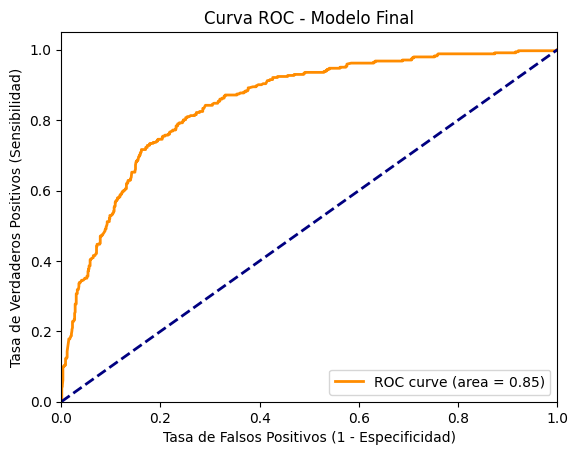

In [7]:
# Predicción de probabilidades en Test
probabilidades_test = modelo_final.predict(X_test)

def roc_grafico(test,pred):
    fpr, tpr, thresholds = metrics.roc_curve(test,pred)
    roc_auc = metrics.auc(fpr, tpr)

    plt.figure()
    lw = 2
    plt.plot(
        fpr,
        tpr,
        color="darkorange",
        lw=lw,
        label="ROC curve (area = %0.2f)" % roc_auc,
    )
    plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
    plt.ylabel("Tasa de Verdaderos Positivos (Sensibilidad)")
    plt.title("Curva ROC - Modelo Final")
    plt.legend(loc="lower right")
    plt.show()

roc_grafico(y_test, probabilidades_test)

In [8]:
def cutoff_youden(y_test, y_pred):
    fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred)
    youden_j = tpr - fpr
    idx = np.argmax(youden_j)
    optimal_threshold = thresholds[idx]
    return optimal_threshold

corte_youden = cutoff_youden(y_test, probabilidades_test)
print(corte_youden)

0.2889655174499228


In [9]:
predicciones_clasificadas = (probabilidades_test > corte_youden).astype(int)

# Matriz de confusión
print("\nMatriz de Confusión (Con el corte óptimo de Youden):")
matriz = metrics.confusion_matrix(y_test, predicciones_clasificadas)
print(matriz)

# Reporte de clasificación
print("\nReporte de Clasificación:")
print(metrics.classification_report(y_test, predicciones_clasificadas))


Matriz de Confusión (Con el corte óptimo de Youden):
[[696 233]
 [ 67 275]]

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.91      0.75      0.82       929
           1       0.54      0.80      0.65       342

    accuracy                           0.76      1271
   macro avg       0.73      0.78      0.73      1271
weighted avg       0.81      0.76      0.78      1271



### 6. Despliegue: Predicción sobre el Test Ciego y Exportación
Pedimos a nuestro modelo entrenado que evalúe a los 690 clientes ciegos del `df_test`.
Aplicando la regla de negocio estricta aprendida en el paso anterior, todo cliente cuya probabilidad de abandono supere nuestro umbral de Youden calculado (28.9%) será clasificado automáticamente como "Fuga" (1). Finalmente, exportamos las predicciones al formato exigido por las bases.


In [10]:
# El modelo predice la probabilidad de fuga para los clientes ciegos del df_test
probabilidades_competicion = modelo_final.predict(df_test)

# Imponemos la regla con Punto de corte óptimo de Youden.
# Todo cliente con probabilidad > corte_youden (0.2889655174499228) será catalogado como "Fuga" (1)
predicciones_competicion = (probabilidades_competicion > corte_youden).astype(int)

# Construimos el dataset final con la estructura que se solicita
df_entrega = pd.DataFrame({
    'ID': df_test.index,
    'Fuga_pred': predicciones_competicion.values
})

# Exportamos el DataFrame a un archivo CSV
nombre_archivo_final = 'FugaPredict_Pytones.csv'
df_entrega.to_csv(nombre_archivo_final, index=False)